# Cargo Monitor: package event classification

**Task:** classify what is happening to the package (normal, carried, shaken, impact, thrown, crushed, hot) from a 2-second window of sensor data.

**Setup:** put `dataset.csv` (exported from the dashboard) and `features.py` in the same folder as this notebook.

**Evaluation is by recording session, never by random rows.** Neighbouring rows are almost identical, so a random split would give a falsely perfect score.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from sklearn.model_selection import StratifiedGroupKFold
from features import FEATURES, make_windows, WINDOW_S, STRIDE_S

df = pd.read_csv("dataset.csv")
print(df.shape)
df.groupby("label").agg(rows=("session", "size"), sessions=("session", "nunique"))

(21683, 22)


,rows,sessions
label,,
carried,2140,3
crushed,968,5
hot,4308,4
impact,2998,8
normal,5988,4
shaken,3516,8
thrown,1765,6


## 1. Data check

In [2]:
calc = np.sqrt(df.ax**2 + df.ay**2 + df.az**2)
bad = ((calc - df.acc_mag).abs() > 0.05).mean()
print(f"rows where acc_mag disagrees with ax/ay/az: {bad:.2%}")
assert bad < 0.01, "Dataset looks corrupted. Re-export it from the backend."
print("missing values:", int(df.isna().sum().sum()))

rows where acc_mag disagrees with ax/ay/az: 0.00%
missing values: 0


## 2. Windowing and features

In [3]:
W = make_windows(df)
LABELS = sorted(W.label.unique())
print(W.shape)
W.groupby("label").agg(windows=("session", "size"), sessions=("session", "nunique"))

(2522, 21)


,windows,sessions
label,,
carried,257,3
crushed,104,5
hot,526,4
impact,318,7
normal,737,4
shaken,379,8
thrown,201,6


## 3. Models and the rule-based baseline

In [4]:
def rule_pred(d):
    return d.rule_alert.replace({"none": "normal"})

def make_models():
    return {
        "DecisionTree": DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=0),
        "RandomForest": RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", random_state=0, n_jobs=-1),
        "ExtraTrees":   ExtraTreesClassifier(n_estimators=300, class_weight="balanced_subsample", random_state=0, n_jobs=-1),
    }

def evaluate(y, p):
    return accuracy_score(y, p), f1_score(y, p, average="macro")

## 4. Test A: train on the first recording day, test on a later one

In [5]:
train, test = W[W.session <= 9], W[W.session >= 10]
print("train windows:", len(train), "| test windows:", len(test))
rows = [("Rules (thresholds)", *evaluate(test.label, rule_pred(test)))]
preds = {}
for name, m in make_models().items():
    m.fit(train[FEATURES], train.label)
    preds[name] = m.predict(test[FEATURES])
    rows.append((name, *evaluate(test.label, preds[name])))
split_a = pd.DataFrame(rows, columns=["model", "accuracy", "macro_F1"]).round(3)
split_a

train windows: 1281 | test windows: 1241


,model,accuracy,macro_F1
0,Rules (thresholds),0.726,0.519
1,DecisionTree,0.918,0.844
2,RandomForest,0.948,0.887
3,ExtraTrees,0.966,0.911


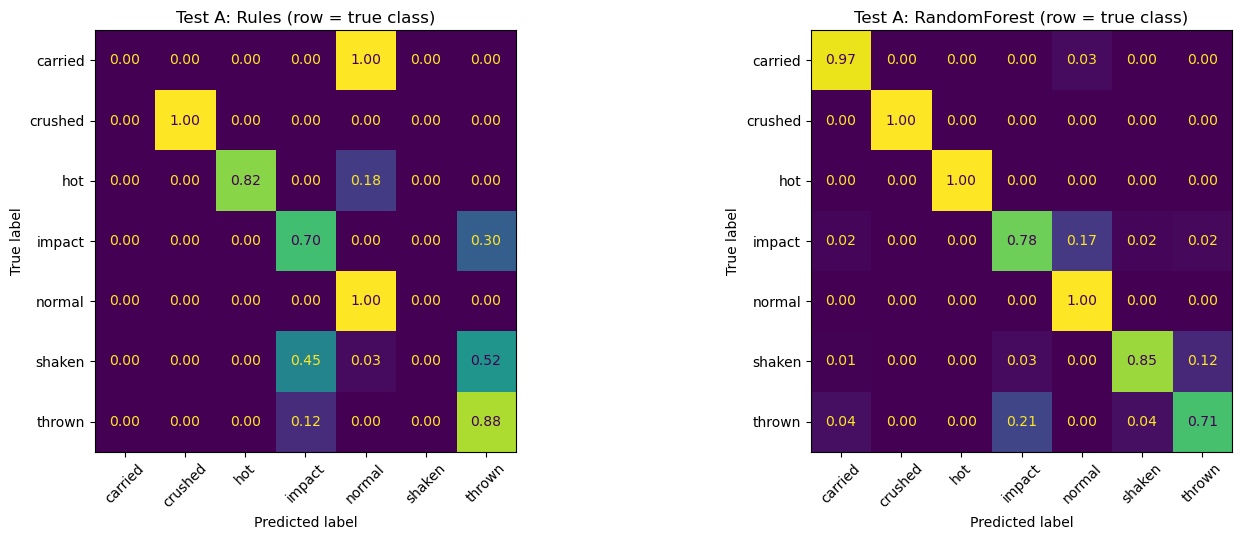

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
for a, (title, p) in zip(ax, [("Rules", rule_pred(test)), ("RandomForest", preds["RandomForest"])]):
    ConfusionMatrixDisplay.from_predictions(test.label, p, labels=LABELS, normalize="true", ax=a,
                                            colorbar=False, xticks_rotation=45, values_format=".2f")
    a.set_title(f"Test A: {title} (row = true class)")
plt.tight_layout(); plt.show()

## 5. Test B: cross-validation by session

In [7]:
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0)
folds = list(sgkf.split(W, W.label, W.session))
scores = {"Rules (thresholds)": [f1_score(W.label.iloc[b], rule_pred(W.iloc[b]), average="macro") for _, b in folds]}
oof = {}
for name in make_models():
    scores[name] = []
    oof[name] = pd.Series(index=W.index, dtype=object)
    for a, b in folds:
        m = make_models()[name].fit(W.iloc[a][FEATURES], W.iloc[a].label)
        p = m.predict(W.iloc[b][FEATURES])
        oof[name].iloc[b] = p
        scores[name].append(f1_score(W.label.iloc[b], p, average="macro"))
split_b = pd.DataFrame({k: [np.mean(v), np.std(v)] for k, v in scores.items()},
                       index=["macro_F1_mean", "macro_F1_std"]).T.round(3)
split_b

,macro_F1_mean,macro_F1_std
Rules (thresholds),0.467,0.036
DecisionTree,0.634,0.078
RandomForest,0.696,0.106
ExtraTrees,0.628,0.106


              precision    recall  f1-score   support

     carried      0.595     0.903     0.717       257
     crushed      0.990     0.981     0.986       104
         hot      1.000     1.000     1.000       526
      impact      0.785     0.827     0.806       318
      normal      0.993     0.791     0.881       737
      shaken      0.797     0.755     0.775       379
      thrown      0.577     0.637     0.605       201

    accuracy                          0.841      2522
   macro avg      0.820     0.842     0.824      2522
weighted avg      0.865     0.841     0.846      2522



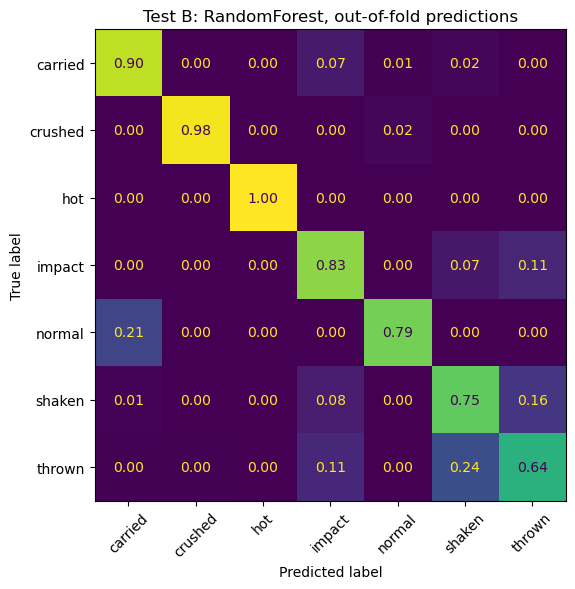

In [8]:
best = "RandomForest"
pred_b = oof[best].astype(str)
print(classification_report(W.label, pred_b, digits=3))
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(W.label, pred_b, labels=LABELS, normalize="true", ax=ax,
                                        colorbar=False, xticks_rotation=45, values_format=".2f")
ax.set_title("Test B: RandomForest, out-of-fold predictions"); plt.tight_layout(); plt.show()

## 6. Which features matter

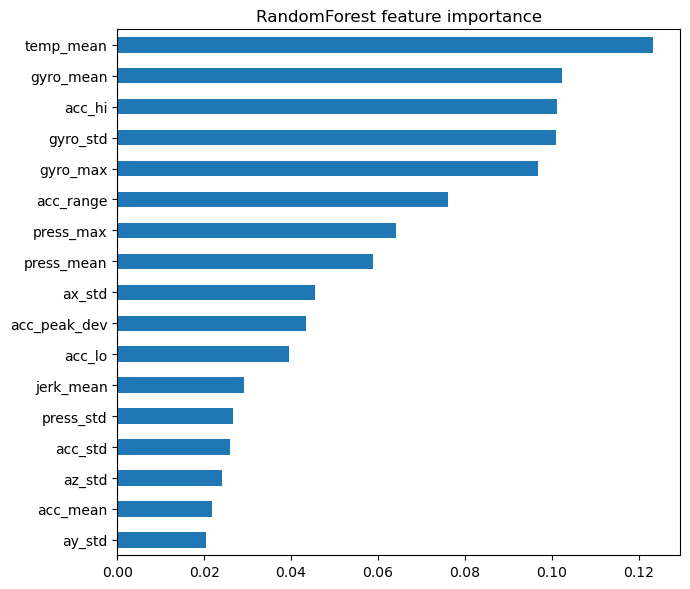

In [9]:
rf = RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", random_state=0, n_jobs=-1).fit(W[FEATURES], W.label)
pd.Series(rf.feature_importances_, index=FEATURES).sort_values().plot.barh(figsize=(7, 6), title="RandomForest feature importance")
plt.tight_layout(); plt.show()

## 7. Save Model

In [10]:
final = RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", random_state=0, n_jobs=-1).fit(W[FEATURES], W.label)
joblib.dump({"model": final, "features": FEATURES, "window_s": WINDOW_S, "stride_s": STRIDE_S,
             "labels": list(final.classes_)}, "model.joblib")
print("saved model.joblib with classes:", list(final.classes_))

saved model.joblib with classes: ['carried', 'crushed', 'hot', 'impact', 'normal', 'shaken', 'thrown']
